In [91]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import joblib

from sklearn.model_selection import (
    train_test_split,
    RandomizedSearchCV,
    GridSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline 
from sklearn.impute import KNNImputer,SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.base import clone

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,precision_score,recall_score,f1_score,
    confusion_matrix,classification_report,
    roc_auc_score,roc_curve,
    ConfusionMatrixDisplay
)

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler,SMOTE,ADASYN

In [2]:
BASE_DIR = Path.cwd().parent
DATA_PATH = BASE_DIR/'data'/'Risk_Alert_Classifier_Dataset.csv'

MODEL_DIR = BASE_DIR/'model'
MODEL_DIR.mkdir(exist_ok=True)

OUTPUT_DIR = BASE_DIR/'outputs'
OUTPUT_DIR.mkdir(exist_ok=True)

# Dataset Understanding & Preparation

In [3]:
df = pd.read_csv(DATA_PATH)

In [4]:

# 1. Dataset ki first 5 rows
display(df.head())

# 2. Dataset ka shape
print("\nRows and Columns:", df.shape)

# 3. Column names
print("\nColumn Names:")
print(df.columns.tolist())

# 4. Data types and missing values
print("\nDataset Information:")
df.info()

# 5. Statistical summary
print("\nStatistical Summary:")
display(df.describe(include="all").T)


,customer_id,age,gender,region,employment_type,annual_income_inr,credit_score,credit_utilization_ratio,missed_payments_12m,avg_late_payment_days,monthly_transaction_count,monthly_spend_inr,cash_advance_count_6m,complaints_last_6m,failed_login_attempts_3m,account_tenure_months,last_transaction_date,debt_balance_inr,risk_status
0,500001,43.0,Female,NaN,Salaried,82242.0,NaN,0.120,1,2.2,39,33889.0,0,2,4,70,2025-09-26,87273,0
1,500002,29.0,Female,Central,Salaried,32769.0,647.0,0.337,1,1.5,11,10853.0,1,1,1,34,2025-11-24,20600,0
2,500003,36.0,Male,East,Salaried,39731.0,727.0,0.175,0,3.9,45,25519.0,2,1,1,74,2025-09-26,47565,0
3,500004,28.0,Male,North,Unemployed,38990.0,553.0,0.472,7,23.3,103,17806.0,1,2,6,72,2025-10-03,43803,1
4,500005,36.0,Female,East,Self-Employed,41043.0,732.0,0.418,1,9.8,95,27114.0,0,1,1,11,2025-10-26,12008,0



Rows and Columns: (4600, 19)

Column Names:
['customer_id', 'age', 'gender', 'region', 'employment_type', 'annual_income_inr', 'credit_score', 'credit_utilization_ratio', 'missed_payments_12m', 'avg_late_payment_days', 'monthly_transaction_count', 'monthly_spend_inr', 'cash_advance_count_6m', 'complaints_last_6m', 'failed_login_attempts_3m', 'account_tenure_months', 'last_transaction_date', 'debt_balance_inr', 'risk_status']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 19 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                4600 non-null   int64  
 1   age                        4460 non-null   float64
 2   gender                     4600 non-null   object 
 3   region                     4498 non-null   object 
 4   employment_type            4456 non-null   object 
 5   annual_income_inr          4434 non-null   f

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,4600.0,NaN,NaN,NaN,502300.5,1328.049949,500001.0,501150.75,502300.5,503450.25,504600.0
age,4460.0,NaN,NaN,NaN,36.360314,10.670375,18.0,28.0,36.0,44.0,75.0
gender,4600,3,Male,2358,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,4498,5,South,1057,NaN,NaN,NaN,NaN,NaN,NaN,NaN
employment_type,4456,5,Salaried,2354,NaN,NaN,NaN,NaN,NaN,NaN,NaN
annual_income_inr,4434.0,NaN,NaN,NaN,41753.518268,17740.750972,15000.0,28980.0,38932.5,51282.5,163002.0
credit_score,4384.0,NaN,NaN,NaN,677.784443,64.888787,405.0,638.0,682.0,721.25,850.0
credit_utilization_ratio,4453.0,NaN,NaN,NaN,0.394721,0.205771,0.002,0.232,0.37,0.531,0.978
missed_payments_12m,4600.0,NaN,NaN,NaN,0.92413,1.300018,0.0,0.0,1.0,1.0,10.0
avg_late_payment_days,4600.0,NaN,NaN,NaN,5.538696,5.624891,0.1,2.1,3.9,6.6,47.1


In [5]:
# Missing values
print("Missing Values:")
print(df.isnull().sum().sort_values(ascending=False))

# Missing values percentage
print("\nMissing Values PR:")
print((df.isnull().mean()*100).round(2).sort_values(ascending=False))

# Duplicate rows
print("\nDuplicate Rows:",df.duplicated().sum())

Missing Values:
credit_score                 216
annual_income_inr            166
credit_utilization_ratio     147
employment_type              144
age                          140
monthly_spend_inr            129
region                       102
customer_id                    0
complaints_last_6m             0
debt_balance_inr               0
last_transaction_date          0
account_tenure_months          0
failed_login_attempts_3m       0
avg_late_payment_days          0
cash_advance_count_6m          0
monthly_transaction_count      0
missed_payments_12m            0
gender                         0
risk_status                    0
dtype: int64

Missing Values PR:
credit_score                 4.70
annual_income_inr            3.61
credit_utilization_ratio     3.20
employment_type              3.13
age                          3.04
monthly_spend_inr            2.80
region                       2.22
customer_id                  0.00
complaints_last_6m           0.00
debt_balance_inr  

In [6]:
print(df["risk_status"].value_counts(dropna=False))
print(df["risk_status"].value_counts(normalize=True)*100)

risk_status
0    4043
1     557
Name: count, dtype: int64
risk_status
0    87.891304
1    12.108696
Name: proportion, dtype: float64


In [7]:
# Features (input column)
X=df.drop(columns=["risk_status","customer_id"])

# Target (output column)
y=df["risk_status"]

print("X shape:",X.shape)
print("y shape:",y.shape)

print("\n Target distribution:")
print(y.value_counts())

X shape: (4600, 17)
y shape: (4600,)

 Target distribution:
risk_status
0    4043
1     557
Name: count, dtype: int64


In [8]:
# convert data column to datetime
t_data = pd.to_datetime(
    X["last_transaction_date"],
    errors="coerce"
)

# create a numeric data feature
reference_data = t_data.max()

X["day_since_last_transaction"] = (
    reference_data - t_data
).dt.days

# Remove original data column
X=X.drop(columns=["last_transaction_date"])

display(X.head())
print("\nupdated shape:",X.shape)

,age,gender,region,employment_type,annual_income_inr,credit_score,credit_utilization_ratio,missed_payments_12m,avg_late_payment_days,monthly_transaction_count,monthly_spend_inr,cash_advance_count_6m,complaints_last_6m,failed_login_attempts_3m,account_tenure_months,debt_balance_inr,day_since_last_transaction
0,43.0,Female,NaN,Salaried,82242.0,NaN,0.120,1,2.2,39,33889.0,0,2,4,70,87273,66
1,29.0,Female,Central,Salaried,32769.0,647.0,0.337,1,1.5,11,10853.0,1,1,1,34,20600,7
2,36.0,Male,East,Salaried,39731.0,727.0,0.175,0,3.9,45,25519.0,2,1,1,74,47565,66
3,28.0,Male,North,Unemployed,38990.0,553.0,0.472,7,23.3,103,17806.0,1,2,6,72,43803,59
4,36.0,Female,East,Self-Employed,41043.0,732.0,0.418,1,9.8,95,27114.0,0,1,1,11,12008,36



updated shape: (4600, 17)


In [9]:
X_train,X_test,y_train,y_test=train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:",X_train.shape)
print("X_test:",X_test.shape)
print("y_train:",y_train.shape)
print("y_test:",y_test.shape)

X_train: (3680, 17)
X_test: (920, 17)
y_train: (3680,)
y_test: (920,)


In [10]:
# Numerical columns
num_cols = X_train.select_dtypes(include=["int64","float64"]).columns.tolist()

# Categorical columns
cat_cols = X_train.select_dtypes(include=["object","category","bool"]).columns.tolist()

print("Numerical Columns:")
print(num_cols)

print("\nCategorycal Columns:")
print(cat_cols)

Numerical Columns:
['age', 'annual_income_inr', 'credit_score', 'credit_utilization_ratio', 'missed_payments_12m', 'avg_late_payment_days', 'monthly_transaction_count', 'monthly_spend_inr', 'cash_advance_count_6m', 'complaints_last_6m', 'failed_login_attempts_3m', 'account_tenure_months', 'debt_balance_inr', 'day_since_last_transaction']

Categorycal Columns:
['gender', 'region', 'employment_type']


In [11]:
print("Missing values in numerical columns:")
print(X_train[num_cols].isnull().sum())

print("\nMissing values in categorical columns:")
print(X_train[cat_cols].isnull().sum())

Missing values in numerical columns:
age                           116
annual_income_inr             132
credit_score                  181
credit_utilization_ratio      118
missed_payments_12m             0
avg_late_payment_days           0
monthly_transaction_count       0
monthly_spend_inr             110
cash_advance_count_6m           0
complaints_last_6m              0
failed_login_attempts_3m        0
account_tenure_months           0
debt_balance_inr                0
day_since_last_transaction      0
dtype: int64

Missing values in categorical columns:
gender               0
region              78
employment_type    115
dtype: int64


# Model Pipeline

In [12]:
# Numerical data preprocessing
num_pipeline = Pipeline([
    ("imputer",KNNImputer(n_neighbors=5)),
    ("scaler",StandardScaler())
])

# Categorycal data preprocessing
cat_pipeline = Pipeline([
    ("imputer",SimpleImputer(strategy="most_frequent")),
    ("onehot",OneHotEncoder(handle_unknown="ignore"))
])

# combine both pipelines
preprocessor = ColumnTransformer([
    ("num",num_pipeline,num_cols),
    ("cat",cat_pipeline,cat_cols)
])

# Tree model Pipeline

In [13]:
# Numerical preprocessing: imputation only
num_tree_pipeline = Pipeline([
    ("imputer", KNNImputer(n_neighbors=5))
])

# Categorical preprocessing: imputation + encoding
cat_tree_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both
tree_preprocessor = ColumnTransformer([
    ("num", num_tree_pipeline, num_cols),
    ("cat", cat_tree_pipeline, cat_cols)
])

# Baseline Model(Logistic Regression)

In [16]:
lr_model=Pipeline([
    ("preprocessor",preprocessor),
    ("model",LogisticRegression(max_iter=1000,random_state=42))
])

Model training completed!
Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       809
           1       1.00      1.00      1.00       111

    accuracy                           1.00       920
   macro avg       1.00      1.00      1.00       920
weighted avg       1.00      1.00      1.00       920


Confusion Matrix:
[[809   0]
 [  0 111]]


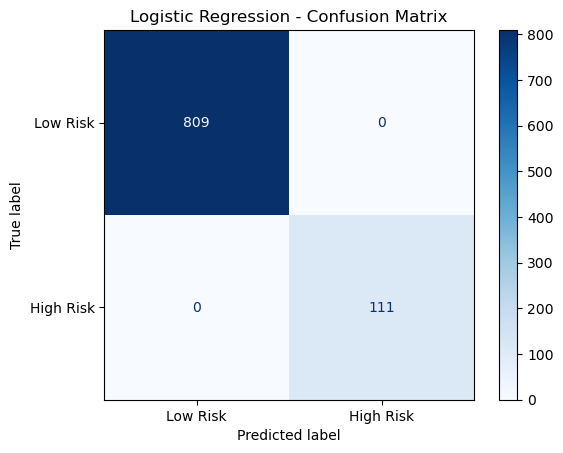


ROC-AUC Score: 1.0


In [19]:

# Train model
lr_model.fit(X_train, y_train)

print("Model training completed!")

# Predict classes
y_pred = lr_model.predict(X_test)

# Predict probability of High Risk (class 1)
y_prob = lr_model.predict_proba(X_test)[:, 1]

# Classification metrics
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

# Plot confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Low Risk", "High Risk"],
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

# ROC-AUC using probabilities
print(
    "\nROC-AUC Score:",
    roc_auc_score(y_test, y_prob)
)


### Type-I error (False Positive): Low Risk customer ne High Risk predict karvo.
### Type-II error (False Negative): High Risk customer ne Low Risk predict karvo.

# Handling Imbalanced Data

In [20]:
print("Training tragey distribution:")
print(y_train.value_counts())


Training tragey distribution:
risk_status
0    3234
1     446
Name: count, dtype: int64


In [24]:
samplers = {
    "Under-sampling":RandomUnderSampler(random_state=42),
    "Over-sampling":RandomOverSampler(random_state=42),
    "SMOTE":SMOTE(random_state=42,k_neighbors=5),
    "ADASYN":ADASYN(random_state=42,n_neighbors=5)
}
print("Sampling methods ready!")

Sampling methods ready!


In [26]:
models = {
    "Baseline LR":lr_model
}

for name,sampler in samplers.items():
    models[name] = ImbPipeline([
        ("preprocessor",clone(preprocessor)),
        ("sampler",clone(sampler)),
        ("model",LogisticRegression(max_iter=1000,random_state=42))
    ])

print("\nAll pipelines created successfully!")


 All pipelines created successfully!


In [30]:
results = []
confusion_matrices = {}
trained_models = {}

for name,model in models.items():
    print("\n"+"="*60)
    print(f"MODEL:{name}")
    print("="*60)

    # Train model
    model.fit(X_train,y_train)
        
    trained_models[name]=model

    # Predict class labels
    y_pred = model.predict(X_test)

    # Probability of High Rish(class1)
    y_prob = model.predict_proba(X_test)[:,1]

    # Calculate confusion matrix
    cm=confusion_matrix(
        y_test,
        y_pred,
        labels=[0,1]
    )

    confusion_matrices[name] = cm

    tn,fp,fn,tp = cm.ravel()

    # Calculate metrics
    accuray = accuracy_score(y_test,y_pred)

    precision = precision_score(y_test,y_pred,pos_label=1,zero_division=0)
    recall = recall_score(y_test,y_pred,pos_label=1,zero_division=0)
    f1 = f1_score(y_test,y_pred,pos_label=1,zero_division=0)

    auc = roc_auc_score(y_test,y_prob)

    # save results
    results.append({
        "Model":name,
        "Accuracy":accuray,
        "High Risk Precision":precision,
        "High Risk Recall":recall,
        "High Risk F1":f1,
        "ROC-AUC":auc,
        "TN":tn,
        "FP":fp,
        "FN":fn,
        "TP":tp
    })

    # Display individua; model report

    print(
        classification_report(
            y_test,y_pred,labels=[0,1],target_names=["Low Risk","High Risk"],
            zero_division=0
        )
    )

    print("Confusion Matrix:")
    print(cm)


    print(f"\nAccuracy: {accuray:.4f}")
    print(f"High Risk Precision: {precision:.4f}")
    print(f"High Risk Recall: {recall:.4f}")
    print(f"High Risk F1: {f1:.4f}")
    
    print(f"\nType-I Error / Fales Positives: {fp}")
    print(f"Type-II Error / False Negatives: {fn}")


MODEL:Baseline LR
              precision    recall  f1-score   support

    Low Risk       1.00      1.00      1.00       809
   High Risk       1.00      1.00      1.00       111

    accuracy                           1.00       920
   macro avg       1.00      1.00      1.00       920
weighted avg       1.00      1.00      1.00       920

Confusion Matrix:
[[809   0]
 [  0 111]]

Accuracy: 1.0000
High Risk Precision: 1.0000
High Risk Recall: 1.0000
High Risk F1: 1.0000

Type-I Error / Fales Positives: 0
Type-II Error / False Negatives: 0

MODEL:Under-sampling
              precision    recall  f1-score   support

    Low Risk       1.00      1.00      1.00       809
   High Risk       0.97      1.00      0.99       111

    accuracy                           1.00       920
   macro avg       0.99      1.00      0.99       920
weighted avg       1.00      1.00      1.00       920

Confusion Matrix:
[[806   3]
 [  0 111]]

Accuracy: 0.9967
High Risk Precision: 0.9737
High Risk Recal

C:\Users\MAYURMAKVANA\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\MAYURMAKVANA\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\MAYURMAKVANA\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\MAYURMAKVANA\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\MAYURMAKVANA\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    h

              precision    recall  f1-score   support

    Low Risk       1.00      1.00      1.00       809
   High Risk       0.98      1.00      0.99       111

    accuracy                           1.00       920
   macro avg       0.99      1.00      0.99       920
weighted avg       1.00      1.00      1.00       920

Confusion Matrix:
[[807   2]
 [  0 111]]

Accuracy: 0.9978
High Risk Precision: 0.9823
High Risk Recall: 1.0000
High Risk F1: 0.9911

Type-I Error / Fales Positives: 2
Type-II Error / False Negatives: 0

MODEL:ADASYN
              precision    recall  f1-score   support

    Low Risk       1.00      1.00      1.00       809
   High Risk       0.98      1.00      0.99       111

    accuracy                           1.00       920
   macro avg       0.99      1.00      0.99       920
weighted avg       1.00      1.00      1.00       920

Confusion Matrix:
[[807   2]
 [  0 111]]

Accuracy: 0.9978
High Risk Precision: 0.9823
High Risk Recall: 1.0000
High Risk F1: 0.9

In [33]:
# ============================================================
# 7. CREATE COMPARISON TABLE
# ============================================================

results_df =pd.DataFrame(results)

results_df  = results_df.sort_values(
    by="High Risk Recall",
    ascending=False
).reset_index(drop=True)

print("\n"+"="*90)
print("Final Prefirmance Comparison")
print("\n"+"="*90)

display(results_df.round(4))


Final Prefirmance Comparison



,Model,Accuracy,High Risk Precision,High Risk Recall,High Risk F1,ROC-AUC,TN,FP,FN,TP
0,Baseline LR,1.0000,1.0000,1.0,1.0000,1.0,809,0,0,111
1,Under-sampling,0.9967,0.9737,1.0,0.9867,1.0,806,3,0,111
2,Over-sampling,0.9978,0.9823,1.0,0.9911,1.0,807,2,0,111
3,SMOTE,0.9978,0.9823,1.0,0.9911,1.0,807,2,0,111
4,ADASYN,0.9978,0.9823,1.0,0.9911,1.0,807,2,0,111


# Tree-Based Classification Models

In [37]:
from sklearn.base import clone

tree_models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

tree_results = []
trained_models = {}

for name, estimator in tree_models.items():

    model = Pipeline([
        ("preprocessor", clone(tree_preprocessor)),
        ("model", estimator)
    ])

    model.fit(X_train, y_train)
    
    y_train_pred = model.predict(X_train)
    y_pred_tree = model.predict(X_test)
    y_prob_tree = model.predict_proba(X_test)[:, 1]

    trained_models[name] = model
    
    cm = confusion_matrix(
        y_test,
        y_pred_tree,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    
    tree_results.append({
        "Model": name,
        "Train Accuracy":accuracy_score(y_train,y_train_pred),
        "Test Accuracy":accuracy_score(y_test,y_pred_tree),
        
        "Precision": precision_score(
            y_test, y_pred_tree, zero_division=0,pos_label=1
        ),
        "Recall": recall_score(
            y_test, y_pred_tree, zero_division=0,pos_label=1
        ),
        "F1 Score": f1_score(
            y_test, y_pred_tree, zero_division=0,pos_label=1
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob_tree),

        "False positives":fp,
        "False Negatives":fn})
    print(f"\n{'=' * 50}")
    print(name)
    print(f"{'=' * 50}")

    print("\nConfusion Matrix:")
    print(cm)

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred_tree,
        labels=[0, 1],
        target_names=["Low Risk", "High Risk"],
        zero_division=0
    ))

# Comparison table
tree_results_df = pd.DataFrame(tree_results)

# Generalization gap
tree_results_df["Generalization Gap"] = (
    tree_results_df["Train Accuracy"]
    - tree_results_df["Test Accuracy"]
)

print("\nFinal Model Comparison:")
display(tree_results_df.round(3))


Decision Tree

Confusion Matrix:
[[793  16]
 [ 14  97]]

Classification Report:
              precision    recall  f1-score   support

    Low Risk       0.98      0.98      0.98       809
   High Risk       0.86      0.87      0.87       111

    accuracy                           0.97       920
   macro avg       0.92      0.93      0.92       920
weighted avg       0.97      0.97      0.97       920


Random Forest

Confusion Matrix:
[[809   0]
 [  2 109]]

Classification Report:
              precision    recall  f1-score   support

    Low Risk       1.00      1.00      1.00       809
   High Risk       1.00      0.98      0.99       111

    accuracy                           1.00       920
   macro avg       1.00      0.99      0.99       920
weighted avg       1.00      1.00      1.00       920


Final Model Comparison:


,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score,ROC-AUC,False positives,False Negatives,Generalization Gap
0,Decision Tree,1.0,0.967,0.858,0.874,0.866,0.927,16,14,0.033
1,Random Forest,1.0,0.998,1.000,0.982,0.991,1.000,0,2,0.002


# Hyperparameter Tuning

In [51]:
dt_pipeline = Pipeline([
    ("preprocessor",clone(tree_preprocessor)),
    ("model",DecisionTreeClassifier(random_state=42))
])

rf_pipeline = Pipeline([
    ("preprocessor",clone(tree_preprocessor)),
    ("model",RandomForestClassifier(random_state=42,n_jobs=1))
])

print("Both pipelines created successfully!")


Both pipelines created successfully!


In [52]:
# RandomizedSearchCV — Decision Tree

dt_params = {
    "model__criterion": ["gini", "entropy", "log_loss"],
    "model__max_depth": [None, 5, 10, 15, 20, 30],
    "model__min_samples_split": [2, 5, 10, 20],
    "model__min_samples_leaf": [1, 2, 4, 8],
    "model__max_features": [None, "sqrt", "log2"],
    "model__class_weight": [None, "balanced"]
}


dt_random = RandomizedSearchCV(
    estimator=dt_pipeline,
    param_distributions=dt_params,
    n_iter=20,
    scoring="recall",
    cv=5,
    random_state=42,
    n_jobs=-1,
    refit=True
)

dt_random.fit(X_train,y_train)

print("Decision Tree Best Parameters:")
print(dt_random.best_params_)

print("\nBest CV Recall:",round(dt_random.best_score_,4))


best_dt_model = dt_random.best_estimator_

Decision Tree Best Parameters:
{'model__min_samples_split': 20, 'model__min_samples_leaf': 8, 'model__max_features': None, 'model__max_depth': 10, 'model__criterion': 'entropy', 'model__class_weight': 'balanced'}

Best CV Recall: 0.9327


In [53]:
# RandomizedSearchCV — Random Forest
rf_params = {
    "model__n_estimators":[100,200,300,400],
    "model__max_depth":[None,5,10,15,20,30],
    "model__min_samples_split":[2,5,10,20],
    "model__min_samples_leaf":[1,2,4,8],
    "model__max_features":[None,"sqrt","log2"],
    "model__class_weight":[None,"balanced","balanced_subsample"]
}

rf_random = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_params,
    n_iter=20,
    scoring="recall",
    cv=5,
    random_state=42,
    n_jobs=-1,
    refit=True
)

rf_random.fit(X_train,y_train)

print("Decision Tree Best Parameters:")
print(rf_random.best_params_)

print("\nBest CV Recall:",round(rf_random.best_score_,4))


best_rf_model = rf_random.best_estimator_

Decision Tree Best Parameters:
{'model__n_estimators': 300, 'model__min_samples_split': 10, 'model__min_samples_leaf': 1, 'model__max_features': 'log2', 'model__max_depth': 5, 'model__class_weight': 'balanced'}

Best CV Recall: 0.9663


In [54]:
# Select best model for GridSearchCV
randomized_results = pd.DataFrame([
    {
        "model":"Decision Tree",
        "Best CV Recall":dt_random.best_score_
    },
    {
        "model":"Random Forest",
        "Best CV Recall":rf_random.best_score_
    }
])

display(randomized_results.round(4))

if dt_random.best_score_>=rf_random.best_score_:
    best_random_name = "Decision Tree"
    best_random_search = dt_random
else:
    best_random_name = "Random Tree"
    best_random_search = rf_random    

print("selected model for GridSearchCV:",best_random_name)

,model,Best CV Recall
0,Decision Tree,0.9327
1,Random Forest,0.9663


selected model for GridSearchCV: Random Tree


In [55]:
grid_params = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [10, 20, 30, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2"],
    "model__class_weight": [None, "balanced"]
}

grid_search = GridSearchCV(
    estimator=clone(best_random_search.best_estimator_),
    param_grid=grid_params,
    scoring="recall",
    cv=5,
    n_jobs=-1,
    refit=True,
    error_score="raise"
)

grid_search.fit(X_train, y_train)

best_grid_model = grid_search.best_estimator_

print("GridSearchCV Best Parameters:")
print(grid_search.best_params_)

print("\nGridSearchCV Best CV Recall:")
print(round(grid_search.best_score_, 4))


GridSearchCV Best Parameters:
{'model__class_weight': 'balanced', 'model__max_depth': 10, 'model__max_features': 'log2', 'model__min_samples_leaf': 4, 'model__min_samples_split': 10, 'model__n_estimators': 100}

GridSearchCV Best CV Recall:
0.9663


In [61]:
# Compare untuned vs tuned models
comparison_models = {
    "Decision Tree - Untuned":dt_pipeline,
    "Random Forest - Untuned":rf_pipeline,
    "Decision Tree  - Randomized":best_dt_model,
    "Random Forest - Randomized":best_rf_model,
    "Final GridSearch Model":best_grid_model
}

tuning_results = []

for name,model in comparison_models.items():
    # Tran untuned  models
    if "Untuned" in name:
        model.fit(X_train,y_train)

    # Test predictions
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:,1]

    # Confusion Matric
    tn,fp,fn,tp = confusion_matrix(
    y_test,y_pred,labels=[0,1]).ravel()

    tuning_results.append({
    "model":name,
    "Accuracy":accuracy_score(y_test,y_pred),
    "High Risk Precision":precision_score(y_test,y_pred,pos_label=1,zero_division=0),
    "High Risk Recall":recall_score(y_test,y_pred,pos_label=1,zero_division=0),
    "High Risk f1":f1_score(y_test,y_pred,pos_label=1,zero_division=0),
    "ROC-AUC":roc_auc_score(y_test,y_pred),
    "False Positives":fp,
    "False Negatives":fn
    })
tuning_results_df = pd.DataFrame(tuning_results)

display(tuning_results_df.sort_values(by="High Risk Recall",ascending=False))

,model,Accuracy,High Risk Precision,High Risk Recall,High Risk f1,ROC-AUC,False Positives,False Negatives
3,Random Forest - Randomized,0.993478,0.948718,1.000000,0.973684,0.996292,6,0
4,Final GridSearch Model,0.995652,0.965217,1.000000,0.982301,0.997528,4,0
1,Random Forest - Untuned,0.997826,1.000000,0.981982,0.990909,0.990991,0,2
2,Decision Tree - Randomized,0.970652,0.844262,0.927928,0.884120,0.952221,19,8
0,Decision Tree - Untuned,0.967391,0.858407,0.873874,0.866071,0.927048,16,14


# Model Evaluation & ROC Analysis

In [77]:
final_models={}

if "lr_model" in globals():
    final_models["Baseline Logistic Regression"] = lr_model

if "models" in globals() and isinstance(models,dict):
    for name,model in models.items():
        final_models[name]=model

if "trained_models" in globals():
    for name,model in trained_models.items():
        final_models[name]=model

if "best_dt_model" in globals():
    final_models["Tuned Decision Tree"] = best_dt_model

if "best_rf_model" in globals():
    final_models["Tuned Random Forest"] = best_rf_model

if "best_grid_model" in globals():
    final_models["GridSearchCV Final Model"]  = best_grid_model

unique_models = {}

for name, model in final_models.items():
    if not any(model is existing for existing in unique_models.values()):
        unique_models[name] = model

final_models = unique_models
print("models availables:")
for name in final_models:
    print(name)

models availables:
Baseline Logistic Regression
Under-sampling
Over-sampling
SMOTE
ADASYN
Decision Tree
Random Forest
Tuned Decision Tree
Tuned Random Forest
GridSearchCV Final Model


In [78]:
X.columns

Index(['age', 'gender', 'region', 'employment_type', 'annual_income_inr',
       'credit_score', 'credit_utilization_ratio', 'missed_payments_12m',
       'avg_late_payment_days', 'monthly_transaction_count',
       'monthly_spend_inr', 'cash_advance_count_6m', 'complaints_last_6m',
       'failed_login_attempts_3m', 'account_tenure_months', 'debt_balance_inr',
       'day_since_last_transaction'],
      dtype='object')

In [80]:
evaluation_results = []
roc_data = {}

for name,model in final_models.items():
    # Predited Probability for high Risk class(1)
    y_prob = model.predict_proba(X_test)[:,1]

    # Default threshold
    y_pred = (y_prob>=0.5).astype(int)

    # Confusion matrix
    tn,fp,fn,tp = confusion_matrix(
    y_test,
    y_pred,
    labels=[0,1]
    ).ravel()

    # Roc curve
    fpr,tpr,thresholds = roc_curve(
    y_test,
    y_prob,
    pos_label=1
    )

    # AUC score
    auc = roc_auc_score(y_test,y_prob)

    roc_data [name]={
    "fpr":fpr,
    "tpr":tpr,
    "auc":auc
    }

    evaluation_results.append({
        "Model":name,
        "Accuracy":accuracy_score(y_test,y_pred),
        "High Risk Precision":precision_score(
            y_test,y_pred,
            pos_label=1,zero_division=0),
        "High Risk Recall":recall_score(
            y_test,y_pred,
            pos_label=1,zero_division=0),
        "High Risk F1":f1_score(
            y_test,y_pred,
            pos_label=1,zero_division=0),
        "AUC-ROC":auc,
        "TN":tn,
        "FP":fp,
        "FN":fn,
        "TP":tp
    })

evaluation_df = pd.DataFrame(evaluation_results)
    
print("MODEL EVALUATION TABLE")

display(
    evaluation_df.sort_values(
        by="AUC-ROC",
        ascending=False
    ).round(4)
)        

MODEL EVALUATION TABLE


,Model,Accuracy,High Risk Precision,High Risk Recall,High Risk F1,AUC-ROC,TN,FP,FN,TP
0,Baseline Logistic Regression,1.0000,1.0000,1.0000,1.0000,1.0000,809,0,0,111
1,Under-sampling,0.9967,0.9737,1.0000,0.9867,1.0000,806,3,0,111
2,Over-sampling,0.9978,0.9823,1.0000,0.9911,1.0000,807,2,0,111
3,SMOTE,0.9978,0.9823,1.0000,0.9911,1.0000,807,2,0,111
9,GridSearchCV Final Model,0.9957,0.9652,1.0000,0.9823,1.0000,805,4,0,111
4,ADASYN,0.9978,0.9823,1.0000,0.9911,1.0000,807,2,0,111
8,Tuned Random Forest,0.9935,0.9487,1.0000,0.9737,0.9999,803,6,0,111
6,Random Forest,0.9967,0.9909,0.9820,0.9864,0.9999,808,1,2,109
7,Tuned Decision Tree,0.9707,0.8443,0.9279,0.8841,0.9821,790,19,8,103
5,Decision Tree,0.9674,0.8584,0.8739,0.8661,0.9270,793,16,14,97


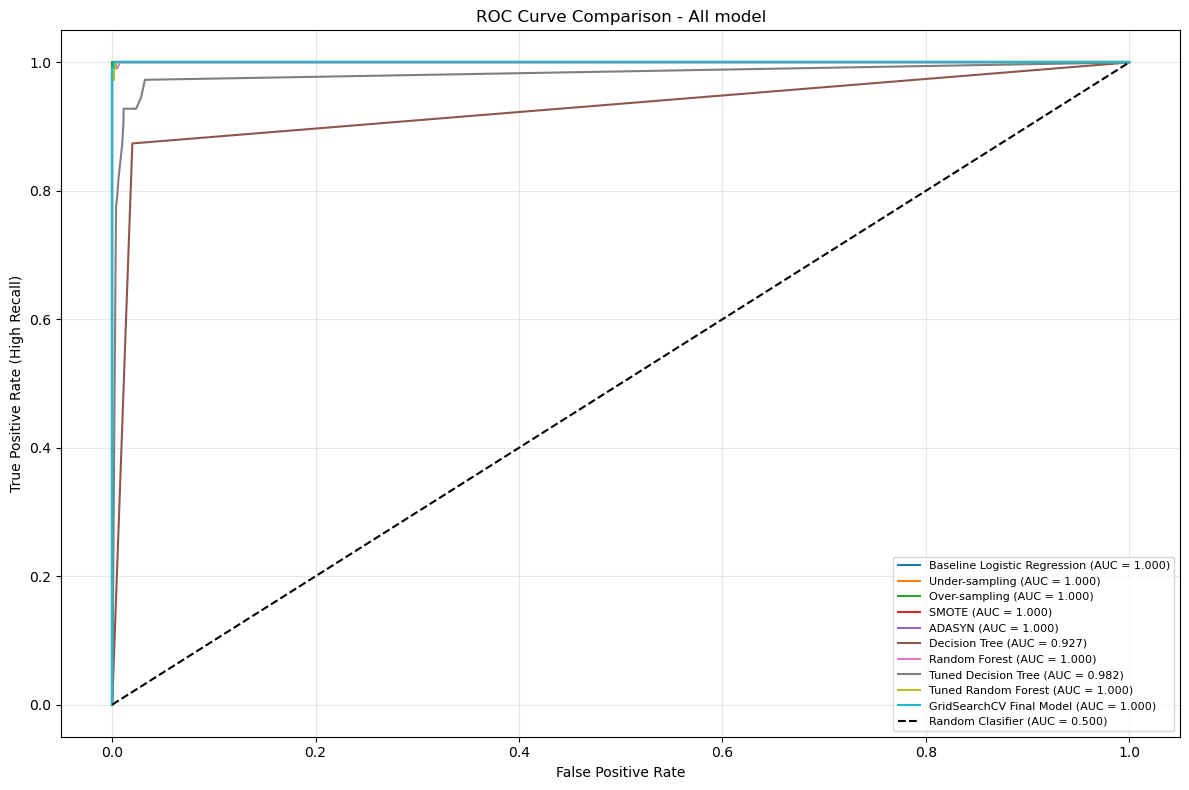

In [81]:
# Plot ROC Curve for all models
plt.figure(figsize=(12,8))
for name,data in roc_data.items():
    plt.plot(
        data["fpr"],
        data["tpr"],
        label=f"{name} (AUC = {data["auc"]:.3f})"
    )

plt.plot(
    [0,1],
    [0,1],
    linestyle="--",
    color="black",
    label="Random Clasifier (AUC = 0.500)"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (High Recall)")
plt.title("ROC Curve Comparison - All model")

plt.legend(
    loc="lower right",
    fontsize=8
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [83]:
ranked_models = evaluation_df.sort_values(
    by=["FN","High Risk Recall","AUC-ROC"],
    ascending=[True,False,False]
).reset_index(drop=True)

print("Models ranked by business priority:")

display(ranked_models[
        ["Model","FN","FP","High Risk Recall","High Risk F1","AUC-ROC"]
    ].round(4)
)
best_row = ranked_models.iloc[0]

best_final_model_name = best_row["Model"]

best_final_model = final_models[best_final_model_name]

print("\n============ BEST FINAL MODEL ==============")
print("Model:",best_final_model_name)
print("False Negatives:",int(best_row["FN"]))
print("False Positives:",int(best_row["FP"]))
print("High Risk Recall:",round(best_row["High Risk Recall"],4))
print("High Risk F1:",round(best_row["High Risk F1"],4))
print("AUC-ROC:",round(best_row["AUC-ROC"],4))

Models ranked by business priority:


,Model,FN,FP,High Risk Recall,High Risk F1,AUC-ROC
0,Baseline Logistic Regression,0,0,1.0000,1.0000,1.0000
1,Under-sampling,0,3,1.0000,0.9867,1.0000
2,Over-sampling,0,2,1.0000,0.9911,1.0000
3,SMOTE,0,2,1.0000,0.9911,1.0000
4,GridSearchCV Final Model,0,4,1.0000,0.9823,1.0000
5,ADASYN,0,2,1.0000,0.9911,1.0000
6,Tuned Random Forest,0,6,1.0000,0.9737,0.9999
7,Random Forest,2,1,0.9820,0.9864,0.9999
8,Tuned Decision Tree,8,19,0.9279,0.8841,0.9821
9,Decision Tree,14,16,0.8739,0.8661,0.9270



============ BEST FINAL MODEL ==============
Model: Baseline Logistic Regression
False Negatives: 0
False Positives: 0
High Risk Recall: 1.0
High Risk F1: 1.0
AUC-ROC: 1.0


In [ ]:
evaluation_df.to_csv(OUTPUT_DIR/"Evaluation.csv",index=False)

# Final Analysis & Reporting

In [88]:
final_report_df = final_report_df.sort_values(
    by=["FN", "High Risk Recall", "AUC-ROC"],
    ascending=[True, False, False]
).reset_index(drop=True)

display(final_report_df.round(4))

,Model,Accuracy,High Risk Precision,High Risk Recall,High Risk F1,AUC-ROC,TN,FP,FN,TP
0,Baseline Logistic Regression,1.0000,1.0000,1.0000,1.0000,1.0000,809,0,0,111
1,Under-sampling,0.9967,0.9737,1.0000,0.9867,1.0000,806,3,0,111
2,Over-sampling,0.9978,0.9823,1.0000,0.9911,1.0000,807,2,0,111
3,SMOTE,0.9978,0.9823,1.0000,0.9911,1.0000,807,2,0,111
4,GridSearchCV Final Model,0.9957,0.9652,1.0000,0.9823,1.0000,805,4,0,111
5,ADASYN,0.9978,0.9823,1.0000,0.9911,1.0000,807,2,0,111
6,Tuned Random Forest,0.9935,0.9487,1.0000,0.9737,0.9999,803,6,0,111
7,Random Forest,0.9967,0.9909,0.9820,0.9864,0.9999,808,1,2,109
8,Tuned Decision Tree,0.9707,0.8443,0.9279,0.8841,0.9821,790,19,8,103
9,Decision Tree,0.9674,0.8584,0.8739,0.8661,0.9270,793,16,14,97


In [90]:
best_final_model = final_models[final_report_df.iloc[0]["Model"]]
best_final_model_name = final_report_df.iloc[0]["Model"]

'Baseline Logistic Regression'

In [92]:
joblib.dump(
    best_final_model,
    MODEL_DIR/"model.joblib"
)

print("Selected model:",best_final_model_name)

print("Evaluation tables and model saved.")

Selected model: Baseline Logistic Regression
Evaluation tables and model saved.


In [94]:
schema = {}

for col in X_train.columns:

    if pd.api.types.is_numeric_dtype(X_train[col]):
        values = pd.to_numeric(X_train[col], errors="coerce")
        valid = values.dropna()

        schema[col] = {
            "type": "numeric",
            "default": float(valid.median()) if len(valid) else 0.0,
            "min": float(valid.min()) if len(valid) else 0.0,
            "max": float(valid.max()) if len(valid) else 100.0
        }

    else:
        values = X_train[col].dropna().astype(str)
        choices = sorted(values.unique().tolist())

        schema[col] = {
            "type": "categorical",
            "default": (
                str(values.mode().iloc[0])
                if not values.mode().empty
                else (choices[0] if choices else "Unknown")
            ),
            "choices": choices[:100]
        }

with open(
    OUTPUT_DIR/"input_schema.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(schema, file, indent=2)

print("Streamlit input schema saved.")


Streamlit input schema saved.
